# アンケートの自由記述を話題ごとに集計して報告する（LLM によるラベル付け）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/11_topics_keywords/survey_free_text.ipynb)

NLP クックブック 11-08 ／ トピックとキーワードの抽出

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

アンケートの自由記述が数百件ある。文埋め込みでクラスタリングして話題を見つけ、各話題に LLM でラベルと説明を付け、件数と代表的な回答を報告用の表と図にしたい。1 件が複数の話題にまたがる回答の扱い、ラベルの粒度の調整、少数意見の取りこぼしの確かめ方も知りたい。

（T4 の GPU ランタイムで、モデルのダウンロードを含めて全体で 10 分程度かかる。）

In [1]:
!pip install -q matplotlib-fontja

In [2]:
import random
import re
import pandas as pd

# このレシピのために作った架空のアンケート（市立図書館の利用者アンケート「図書館へのご意見・ご要望をご自由にお書きください」）。
# 話題ごとに手で書いた文を 1 つ（単一の話題）か 2 つ（複数の話題）つないで回答にした。実在の回答ではない。
# 正解の話題 (true) は、最後の答え合わせにだけ使う
FRAG = {
    "開館時間": [
        "平日も夜9時まで開いていると、仕事帰りに寄れて助かります。", "閉館が18時なので、会社員はほとんど利用できません。",
        "月曜休館をやめて、別の曜日を休みにしてほしい。", "土日だけでも朝9時より早く開けてもらえないでしょうか。",
        "年末年始の休館期間が長すぎると思います。", "夜間開館の日を増やしてほしいです。", "開館時間を延長してください。",
        "祝日に閉まっていることがあり、何度か無駄足になりました。", "試験期間中だけでも閉館時間を遅くしてほしい。",
        "館内整理日がいつなのか分かりにくいです。", "日曜日は17時に閉まるのが早すぎる。", "朝早くから開いているのはありがたい。",
        "分館は平日の昼間しか開いていないので、もう少し時間を広げてほしい。", "仕事が終わってから行くと、もう閉まっています。"],
    "座席": [
        "自習席が少なく、土日は朝から満席です。", "学生が席を長時間占領していて、本を読む場所がない。", "座席の予約制を導入してほしい。",
        "窓際の閲覧席は明るくて気に入っています。", "机が狭くてノートパソコンと本を同時に広げられない。",
        "椅子が硬く、長く座っていると腰が痛くなります。", "グループで話し合いができる部屋がほしい。",
        "荷物だけ置いて席を取る人がいて困っている。", "新聞コーナーのソファーがいつも同じ人で埋まっている。", "学習室を増やしてほしいです。",
        "席数が足りないので、使っていない会議室を開放してはどうか。", "閲覧席の照明が暗くて字が読みにくい。",
        "一人用の仕切りのある席があると集中できる。", "夏休みは中高生で席が全く空いていない。"],
    "蔵書": [
        "新刊の入荷が遅く、話題の本はいつも予約待ちです。", "専門書が古いものばかりで、最新の版がない。", "雑誌の種類を増やしてほしい。",
        "リクエストした本をすぐに購入してもらえて嬉しかった。", "人気の小説を何冊か複本で置いてほしい。",
        "郷土資料が充実しているのはこの図書館の良いところだと思う。", "プログラミングやITの本が少ない。",
        "漫画も少し置いてもらえると若い人が来やすいと思う。", "電子書籍の貸出を始めてほしい。",
        "資格試験の問題集が古い年度のものしかない。", "大活字本をもっと増やしてほしい。", "同じシリーズの途中の巻が抜けていることが多い。",
        "古い本が汚れていて、手に取る気になれないものがある。", "ビジネス書の棚をもう少し充実させてほしい。"],
    "予約・Web": [
        "ホームページの蔵書検索が使いにくい。", "予約した本の取り置き期限が短すぎる。", "スマホから予約や延長ができるようにしてほしい。",
        "予約の順番があと何人か分かるようにしてほしい。", "貸出の延長手続きがネットでできるのは便利です。",
        "Webサイトのデザインが古く、どこに何があるか分からない。", "予約の本が届いたメールがよく迷惑メールに入ってしまう。",
        "パスワードを忘れたときの再発行が窓口でしかできないのは不便。", "自動貸出機の操作がわかりにくく、毎回職員さんを呼んでいる。",
        "予約できる冊数の上限を増やしてほしい。", "検索結果に貸出中かどうかがすぐ表示されないのが不便です。",
        "カードを忘れてもスマホの画面で借りられるようにしてほしい。"],
    "職員": [
        "カウンターの職員さんがいつも親切で、気持ちよく利用できます。", "レファレンスで調べ物を手伝っていただき、大変助かりました。",
        "一部の職員の言葉づかいが冷たく感じることがある。", "本の場所を尋ねたら、棚まで案内してくれてありがたかった。",
        "窓口が混んでいるのに一人しか対応していないことがある。", "子どもにも優しく声をかけてくださり感謝しています。",
        "質問しても「分かりません」で終わってしまい残念だった。", "司書の方のおすすめ本の展示がいつも楽しみです。",
        "返却が少し遅れただけで強い口調で注意された。", "職員の皆さんの丁寧な対応に感謝しています。", "電話の問い合わせにも丁寧に答えてもらえた。"],
    "駐車場・交通": [
        "駐車場が狭く、土日は停められないことが多い。", "駐輪場に屋根がなく、雨の日は自転車が濡れる。",
        "駅から遠いので、バスの本数を増やしてほしい。", "駐車場の無料時間を2時間に延ばしてほしい。",
        "駐車場の出入口が狭くて車をぶつけそうになる。", "最寄りのバス停から図書館までの道が分かりにくい。",
        "駐輪場がいっぱいで、歩道に自転車があふれている。", "近くの市営駐車場と提携してほしい。", "送迎の車が入口前に停まっていて危ない。"],
    "静かさ・マナー": [
        "館内で携帯電話で話している人がいて気になる。", "中高生のおしゃべりがうるさいときがある。", "静かな環境で読書ができて満足しています。",
        "イヤホンの音漏れを注意してほしい。", "飲食禁止のはずなのに、お菓子を食べている人がいる。", "職員同士の私語が意外と響いている。",
        "キーボードの音が気になるので、パソコンを使える席を分けてほしい。", "寝ている人のいびきが気になることがある。",
        "マナーの悪い利用者には、もっと注意してほしい。"],
    "Wi-Fi・電源": [
        "館内のWi-Fiがすぐ切れる。", "電源の使える席を増やしてほしい。", "無料Wi-Fiがあるのは便利です。",
        "Wi-Fiの接続に毎回登録が必要で面倒。", "パソコン席のコンセントが壊れていることがある。",
        "オンライン会議に使えるくらい通信速度を上げてほしい。", "スマホの充電ができる場所があると助かる。", "調べ物用のパソコンが古くて動作が遅い。"],
    "子ども・イベント": [
        "子ども向けのおはなし会を毎回楽しみにしています。", "児童書コーナーをもう少し広くしてほしい。",
        "小さい子どもが少し声を出しても気にならないスペースがあると助かる。", "夏休みの工作教室に参加して、子どもが本に興味を持つようになった。",
        "大人向けの講座や読書会も開いてほしい。", "授乳室とおむつ替えの場所を分かりやすくしてほしい。",
        "絵本の数が多くて、子どもと一緒に選ぶのが楽しい。", "中高生向けの本のコーナーがあるとよい。"],
    # 少数意見: 件数が少なく、ほかの話題と同じ語（カウンター、棚、本）を含む
    "バリアフリー": [
        "車いすだとカウンターが高くて、職員さんと話しにくい。", "二階へのエレベーターがなく、足の悪い母は一階しか利用できない。",
        "書架の間が狭くて、車いすでは奥の棚まで行けません。", "入口のスロープが急で、一人では上れない。",
        "多目的トイレが一階に一か所しかないので増やしてほしい。"],
    "外国語": [
        "英語や中国語の本がほとんどないので、外国出身の家族は使いにくい。", "館内の案内表示に英語も入れてほしい。",
        "やさしい日本語の本のコーナーがあると、日本語を勉強している人に役立つと思う。", "利用案内のパンフレットを多言語で作ってほしい。"],
}
rng = random.Random(0)
rows = [{"text": f, "true": [t]} for t, fs in FRAG.items() for f in fs]
main = [t for t in FRAG if t not in ("バリアフリー", "外国語")]
for _ in range(80):                                     # 2 つの話題にまたがる回答
    t1, t2 = rng.sample(main, 2)
    rows.append({"text": rng.choice(FRAG[t1]) + rng.choice(FRAG[t2]), "true": [t1, t2]})
for t in ["特になし", "特にありません。", "なし", "とくにないです", "特にない", "なし。", "今のままで十分です。", "いつもありがとうございます。"]:
    rows.append({"text": t, "true": []})
for r in rows:                                           # 前置きや結びの言葉を付けて、表現を少しばらつかせる
    if r["true"]:
        r["text"] = rng.choice(["", "", "", "いつも利用しています。", "週に一度は来ています。"]) + r["text"]
        r["text"] += rng.choice(["", "", "", "よろしくお願いします。", "ご検討ください。"])
df = pd.DataFrame(rows).sample(frac=1, random_state=0).reset_index(drop=True)
print(len(df), "件")
df.head(8)

196 件


,text,true
0,館内のWi-Fiがすぐ切れる。,[Wi-Fi・電源]
1,分館は平日の昼間しか開いていないので、もう少し時間を広げてほしい。,[開館時間]
2,郷土資料が充実しているのはこの図書館の良いところだと思う。,[蔵書]
3,荷物だけ置いて席を取る人がいて困っている。送迎の車が入口前に停まっていて危ない。ご検討ください。,"[座席, 駐車場・交通]"
4,予約できる冊数の上限を増やしてほしい。席数が足りないので、使っていない会議室を開放してはどう...,"[予約・Web, 座席]"
5,閉館が18時なので、会社員はほとんど利用できません。本の場所を尋ねたら、棚まで案内してくれて...,"[開館時間, 職員]"
6,パソコン席のコンセントが壊れていることがある。閲覧席の照明が暗くて字が読みにくい。,"[Wi-Fi・電源, 座席]"
7,いつも利用しています。レファレンスで調べ物を手伝っていただき、大変助かりました。スマホの充電...,"[職員, Wi-Fi・電源]"


In [3]:
import json
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# 「特になし」のような中身のない回答は、件数だけ数えて分析から除く
# 「今のままで十分です。」やお礼だけの回答は正規表現では除かず、LLM に話題なしと判断させる（手順 4 でラベルなしに出る）
empty = df["text"].str.fullmatch(r"(特に|とくに)?(なし|ない|ないです|ありません)。?")
print("中身のない回答:", empty.sum(), "件")
ans = df[~empty].reset_index(drop=True)

torch.manual_seed(0)
name = "Qwen/Qwen3-4B-Instruct-2507"     # Apache 2.0。思考 (thinking) をしない版
tokenizer = AutoTokenizer.from_pretrained(name)
tokenizer.padding_side = "left"           # バッチ生成では左パディング
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
llm = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="auto").eval()

@torch.no_grad()
def generate(prompts, max_new_tokens=100, batch_size=16):
    """プロンプトのリストをバッチで貪欲生成する（大規模言語モデルの章の「複数のプロンプトをまとめてバッチ生成する」と同じ）"""
    outs = []
    for i in range(0, len(prompts), batch_size):
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": p}], add_generation_prompt=True, tokenize=False)
                 for p in prompts[i:i + batch_size]]
        enc = tokenizer(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(llm.device)
        out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id)
        outs += [s.strip() for s in tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return outs

def extract_json(text):
    """最初の JSON オブジェクトを取り出す（大規模言語モデルの章の「LLM の出力から JSON を取り出して検証する」と同じ考え方）"""
    start = text.find("{")
    try:
        return json.JSONDecoder().raw_decode(text[start:])[0] if start >= 0 else {}
    except json.JSONDecodeError:
        return {}

中身のない回答: 6 件


In [4]:
# 1. 回答ごとに、意見の対象になっている話題を短い句で LLM に書き出させる（1 件に話題が複数あれば複数。Colab の T4 で 1〜2 分）
PHRASE_PROMPT = """次の図書館の利用者アンケートの回答から、意見や要望の対象になっている話題を、短い名詞句（15 字以内）で書き出してください。
話題が複数あればすべて書き出し、1 行に 1 つずつ「- 」で始めてください。挨拶やお礼だけの言葉は話題にしません。話題がなければ「- なし」と書いてください。

回答: {text}"""
outs = generate([PHRASE_PROMPT.format(text=t) for t in ans["text"]], max_new_tokens=60)
ans["phrases"] = [[p for p in (re.sub(r"^[-・\s]+", "", line).strip() for line in o.split("\n")) if p and p != "なし"] for o in outs]
print("句の数の分布:", ans["phrases"].map(len).value_counts().sort_index().to_dict())
ans[["text", "phrases"]].head(6)

句の数の分布: {0: 2, 1: 94, 2: 88, 3: 6}


,text,phrases
0,館内のWi-Fiがすぐ切れる。,[Wi-Fiの安定性]
1,分館は平日の昼間しか開いていないので、もう少し時間を広げてほしい。,[開館時間]
2,郷土資料が充実しているのはこの図書館の良いところだと思う。,[郷土資料]
3,荷物だけ置いて席を取る人がいて困っている。送迎の車が入口前に停まっていて危ない。ご検討ください。,"[荷物置き, 送迎車の停車, センターの安全]"
4,予約できる冊数の上限を増やしてほしい。席数が足りないので、使っていない会議室を開放してはどう...,"[予約冊数上限, 会議室開放]"
5,閉館が18時なので、会社員はほとんど利用できません。本の場所を尋ねたら、棚まで案内してくれて...,"[閉館時間, 本の場所案内]"


In [5]:
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans

# 2. 句を文埋め込みにしてクラスタリングする。回答の文全体より、言い回しや挨拶に引きずられにくい
ph = ans[["phrases"]].explode("phrases").dropna().reset_index().rename(columns={"index": "answer", "phrases": "phrase"})
model = SentenceTransformer("cl-nagoya/ruri-v3-310m")   # Apache 2.0。日本語の文埋め込みモデル。クラスタリングには「トピック: 」を前に付ける
emb = model.encode(["トピック: " + t for t in ph["phrase"]], normalize_embeddings=True, batch_size=64, show_progress_bar=False)

K = 15          # 少し細かめに分けておき、あとでまとめる（粒度の調整を参照）
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(emb)
ph["cluster"] = km.labels_
cent = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)
ph["sim"] = (emb * cent[ph["cluster"]]).sum(axis=1)        # 自分のクラスタの中心とのコサイン類似度
print(len(ph), "個の句")
for c in ph["cluster"].value_counts().index:
    g = ph[ph.cluster == c].sort_values("sim", ascending=False)
    print(f"[{c:2}] {len(g):3} 個 | " + "、".join(g["phrase"].drop_duplicates().head(6)))

288 個の句
[12]  47 個 | 貸出延長手続き、貸出状況の表示、電子書籍貸出、予約冊数上限、予約冊数の上限、蔵書検索
[ 0]  34 個 | 利用時間、対応人数、利用頻度、Wi-Fi登録、Wi-Fi、通信速度
[ 3]  31 個 | 開館時間、閉館時間、休館日、閉館日、夜間開館、祝日閉館
[ 1]  30 個 | おすすめ本の展示、児童書コーナー、児童書コーナー広さ、絵本の数、本の場所、中高生向け本コーナー
[ 8]  27 個 | パソコン席コンセント、電源席、パソコン席のコンセント、コンセント、電源付き席、電源設備
[ 4]  26 個 | 座席予約、席の確保、席の占有問題、席の占領問題、予約順番の表示、席数
[13]  19 個 | 職員の言葉づかい、職員の対応、職員の私語、職員との対話のしやすさ、グループ話し合い部屋、子どもへの対応
[ 5]  15 個 | 送迎車の停車、送迎車の停車場所、送迎車の位置、バス本数、バスの本数、バス停からのアクセス
[ 2]  14 個 | 学習室増設、学習室、自習席、会議室開放、自習席数、講座開催
[ 9]  10 個 | 駐車場、駐車場提携、駐車場出入口、駐車場無料時間
[11]   9 個 | IT書籍不足、IT書籍の不足、IT本が少ない、IT本、プログラミング本、シリーズの巻数不足
[10]   8 個 | 駐輪場屋根、駐輪場の屋根、駐輪場、自転車の配置、自転車の雨対策
[ 6]   8 個 | 専門書の更新、新刊入荷、問題集の更新、専門書の最新版、杂誌の種類、パソコン更新
[ 7]   7 個 | 電話音の影響、電話音の問題、中高生の騒音、音漏れ、キーボード音
[14]   3 個 | 道が分かりにくい


In [6]:
# 3. 各クラスタに LLM でラベルと説明を付ける。中心に近い句 10 個とそれ以外から無作為に 10 個、元の回答 3 件を見せる
LABEL_PROMPT = """次は、図書館の利用者アンケートの自由記述から取り出した話題のうち、似たものを集めたものです。
これら全体に共通する話題を表すラベル（12 字以内）と、どのような意見があるかの説明（40 字以内）を考えてください。
一部の話題だけに当てはまる狭いラベルにはしないでください。
出力は {{"label": "...", "description": "..."}} の形の JSON だけにしてください。

話題: {phrases}

回答の例:
{answers}"""
prompts = []
for c in range(K):
    g = ph[ph.cluster == c].sort_values("sim", ascending=False).drop_duplicates("phrase")
    phrases = list(g["phrase"].head(10)) + list(g["phrase"].iloc[10:].sample(min(10, max(len(g) - 10, 0)), random_state=0))
    answers = "\n".join("- " + ans["text"][a] for a in g["answer"].drop_duplicates().head(3))
    prompts.append(LABEL_PROMPT.format(phrases="、".join(phrases), answers=answers))
info = [extract_json(o) for o in generate(prompts, max_new_tokens=100)]
codebook = pd.DataFrame({"cluster": range(K), "ラベル": [d.get("label", f"クラスタ{c}") for c, d in enumerate(info)],
                         "説明": [d.get("description", "") for d in info], "句の数": ph["cluster"].value_counts().sort_index().values})
codebook

,cluster,ラベル,説明,句の数
0,0,対応の質,窓口や個人対応の丁寧さや効率についての意見,34
1,1,読書環境の整備,本の配置やスペースの改善を求める意見,30
2,2,学習スペースの整備,利用しやすさと充実度を求める,14
3,3,開館時間の見直し,開館時間の拡充や休館日の調整を求める,31
4,4,座席のマナーと管理,席の確保や占有、マナーに関する課題を指摘。,26
5,5,送迎バスの運用,停車場所や混雑、アクセスについての懸念が多数,15
6,6,資料の更新,最新の資料が不足している,8
7,7,館内音の問題,利用中の音の影響についての懸念,7
8,8,設備の整備,電源や照明、スペースの改善を求める意見,27
9,9,駐車場の利用改善,駐車場の容量やアクセス、利用便利性についての改善が求められている,10


In [7]:
# 4. ラベルの一覧（コードブック）を選択肢にして、全回答に当てはまるラベルをすべて LLM に選ばせる（マルチラベル。Colab の T4 で 2〜3 分）
choices = "\n".join(f"{i}. {r.ラベル}: {r.説明}" for i, r in enumerate(codebook.itertuples(), 1))
MULTI_PROMPT = """次の図書館の利用者アンケートの回答が触れている話題を、下の一覧からすべて選んでください。
番号だけをカンマ区切りで出力してください（例: 2,5）。どれにも当てはまらない場合は 0 と出力してください。

話題:
{choices}

回答: {text}"""
outs = generate([MULTI_PROMPT.format(choices=choices, text=t) for t in ans["text"]], max_new_tokens=12)
ans["labels"] = [sorted({int(x) - 1 for x in re.findall(r"\d+", o) if 0 < int(x) <= K}) for o in outs]
ans["from_cluster"] = [sorted(set(ph[ph.answer == i]["cluster"])) for i in range(len(ans))]   # 句のクラスタから決めたラベル
print("ラベルの数の分布:", ans["labels"].map(len).value_counts().sort_index().to_dict())
print("句のクラスタと LLM の選択が一致した回答:", f"{np.mean([a == b for a, b in zip(ans.labels, ans.from_cluster)]):.0%}")
print(f"最大メモリ: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

ラベルの数の分布: {0: 13, 1: 91, 2: 81, 3: 5}
句のクラスタと LLM の選択が一致した回答: 41%
最大メモリ: 11.3 GB


ラベル,説明,回答数,割合,代表的な回答
開館時間の見直し,開館時間の拡充や休館日の調整を求める,33,17.4%,分館は平日の昼間しか開いていないので、もう少し時間を広げてほしい。 / 平日も夜9時まで開いていると、仕事帰りに寄れて助かります。
職員の対応と環境,職員の言葉づかいや対応、子どもやグループへの配慮が求められる。,31,16.3%,一部の職員の言葉づかいが冷たく感じることがある。 / いつも利用しています。貸出の延長手続きがネットでできるのは便利です。一部の職員の言葉づかいが冷たく感じることがある。
利用手順のしやすさ,貸出や検索の手順がわかりやすく、操作が簡単であることを求める,26,13.7%,週に一度は来ています。貸出の延長手続きがネットでできるのは便利です。ご検討ください。 / 検索結果に貸出中かどうかがすぐ表示されないのが不便です。絵本の数が多くて、子どもと一緒に選ぶのが楽しい。
設備の整備,電源や照明、スペースの改善を求める意見,25,13.2%,パソコン席のコンセントが壊れていることがある。 / スマホの充電ができる場所があると助かる。ご検討ください。
読書環境の整備,本の配置やスペースの改善を求める意見,22,11.6%,中高生向けの本のコーナーがあるとよい。よろしくお願いします。 / 大活字本をもっと増やしてほしい。ご検討ください。
学習スペースの整備,利用しやすさと充実度を求める,19,10.0%,学習室を増やしてほしいです。よろしくお願いします。 / 席数が足りないので、使っていない会議室を開放してはどうか。
座席のマナーと管理,席の確保や占有、マナーに関する課題を指摘。,18,9.5%,座席の予約制を導入してほしい。 / 学生が席を長時間占領していて、本を読む場所がない。
案内が不明確,道案内が不明瞭で利用困難,18,9.5%,いつも利用しています。最寄りのバス停から図書館までの道が分かりにくい。よろしくお願いします。 / 最寄りのバス停から図書館までの道が分かりにくい。プログラミングやITの本が少ない。ご検討ください。
館内音の問題,利用中の音の影響についての懸念,17,8.9%,週に一度は来ています。中高生のおしゃべりがうるさいときがある。ご検討ください。 / イヤホンの音漏れを注意してほしい。よろしくお願いします。
資料の更新,最新の資料が不足している,14,7.4%,専門書が古いものばかりで、最新の版がない。司書の方のおすすめ本の展示がいつも楽しみです。よろしくお願いします。 / 新刊の入荷が遅く、話題の本はいつも予約待ちです。


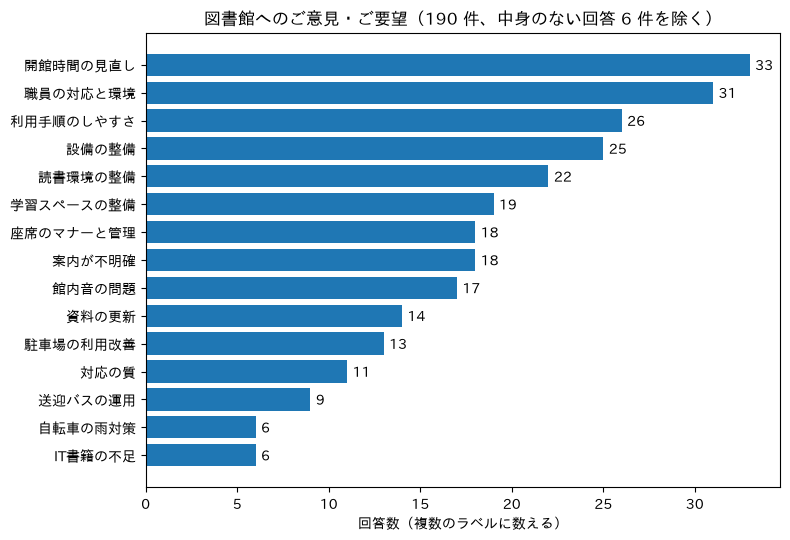

In [8]:
import matplotlib.pyplot as plt
import matplotlib_fontja

# 5. 報告用の表と図: ラベルごとの回答数（1 件が複数のラベルに数えられる）、割合、説明、代表的な回答
def representatives(c, n=2):
    """そのラベルが付いた回答のうち、ほかのラベルが少なく、句がクラスタの中心に近い順に n 件"""
    g = ph[(ph.cluster == c) & ph.answer.map(lambda a: c in ans["labels"][a])].copy()
    g["n_labels"] = g["answer"].map(lambda a: len(ans["labels"][a]))
    g = g.sort_values(["n_labels", "sim"], ascending=[True, False])
    return " / ".join(ans["text"][a] for a in g["answer"].drop_duplicates().head(n))

report = codebook[["ラベル", "説明"]].copy()
report["回答数"] = [sum(c in l for l in ans["labels"]) for c in range(K)]
report["割合"] = report["回答数"] / len(ans)
report["代表的な回答"] = [representatives(c) for c in range(K)]
report = report.sort_values("回答数", ascending=False)
report.to_csv("survey_report.csv", index=False, encoding="utf-8-sig")   # Excel で開けるように BOM 付きで保存
display(report.style.format({"割合": "{:.1%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(report["ラベル"][::-1], report["回答数"][::-1], color="tab:blue")
for i, n in enumerate(report["回答数"][::-1]):
    ax.text(n + 0.3, i, str(n), va="center")
ax.set_xlabel("回答数（複数のラベルに数える）")
ax.set_title(f"図書館へのご意見・ご要望（{len(ans)} 件、中身のない回答 {empty.sum()} 件を除く）")
plt.tight_layout(); plt.savefig("survey_topics.png", dpi=150); plt.show()

In [9]:
# 6. 粒度の調整: 細かいラベルを、LLM に大きな分類にまとめさせる（どの分類にも 1 回ずつ入っているかを確かめる）
GROUP_PROMPT = """次は、図書館の利用者アンケートの自由記述から作った話題の一覧です。これらを 6 個程度の大きな分類にまとめてください。
すべての番号をどれか 1 つの分類に入れ、{{"分類名": [番号, ...], ...}} の形の JSON だけを出力してください。

{items}"""
items = "\n".join(f"{i}. {r.ラベル}: {r.説明}" for i, r in enumerate(codebook.itertuples(), 1))
groups = {g: [int(c) - 1 for c in cs] for g, cs in extract_json(generate([GROUP_PROMPT.format(items=items)], max_new_tokens=200)[0]).items()}
assigned = sorted(c for cs in groups.values() for c in cs)
print("すべてのラベルが 1 回ずつ入っている:", assigned == list(range(K)))
for g, cs in groups.items():
    n = sum(any(c in l for c in cs) for l in ans["labels"])
    print(f"{g}（{n} 件）: " + "、".join(codebook["ラベル"][c] for c in cs if 0 <= c < K))

すべてのラベルが 1 回ずつ入っている: False
対応の質（35 件）: 対応の質、職員の対応と環境
学習環境の整備（42 件）: 学習スペースの整備、設備の整備
開館時間とアクセス（56 件）: 開館時間の見直し、送迎バスの運用、駐車場の利用改善、自転車の雨対策
資料の充実（19 件）: 資料の更新、IT書籍の不足
利用手順と案内（43 件）: 利用手順のしやすさ、案内が不明確
座席とマナー（18 件）: 座席のマナーと管理


In [10]:
# 7. 少数意見の取りこぼしを確かめる
# (1) LLM がどのラベルにも当てはまらないとした回答: コードブックにない話題の候補
print("■ どのラベルにも当てはまらない回答:", (ans["labels"].map(len) == 0).sum(), "件")
for t in ans[ans["labels"].map(len) == 0]["text"]:
    print("  ", t)
# (2) 自分のクラスタの中心から遠い句: クラスタになじまない意見の候補
print("■ クラスタの中心から遠い句")
for _, r in ph.nsmallest(10, "sim").iterrows():
    print(f"  {r.sim:.3f} {r.phrase} [{codebook['ラベル'][r.cluster]}] ← {ans['text'][r.answer]}")
# (3) クラスタ数を増やしたときに現れる小さなクラスタ
lab = KMeans(n_clusters=30, n_init=10, random_state=0).fit_predict(emb)
size = pd.Series(lab).value_counts()
print("■ K=30 で句が 4 個以下のクラスタ")
for c in size[size <= 4].index:
    print(f"  {size[c]} 個: " + "、".join(ph["phrase"][lab == c]))

■ どのラベルにも当てはまらない回答: 13 件
   郷土資料が充実しているのはこの図書館の良いところだと思う。
   司書の方のおすすめ本の展示がいつも楽しみです。よろしくお願いします。
   予約できる冊数の上限を増やしてほしい。ご検討ください。
   夏休みの工作教室に参加して、子どもが本に興味を持つようになった。ご検討ください。
   週に一度は来ています。大人向けの講座や読書会も開いてほしい。
   予約の本が届いたメールがよく迷惑メールに入ってしまう。
   今のままで十分です。
   いつも利用しています。子ども向けのおはなし会を毎回楽しみにしています。
   入口のスロープが急で、一人では上れない。
   リクエストした本をすぐに購入してもらえて嬉しかった。
   いつもありがとうございます。
   オンライン会議に使えるくらい通信速度を上げてほしい。よろしくお願いします。
   電子書籍の貸出を始めてほしい。
■ クラスタの中心から遠い句
  0.876 椅子の硬度 [座席のマナーと管理] ← 椅子が硬く、長く座っていると腰が痛くなります。よろしくお願いします。
  0.881 小説の種類 [利用手順のしやすさ] ← いつも利用しています。人気の小説を何冊か複本で置いてほしい。よろしくお願いします。
  0.881 飲食禁止違反 [送迎バスの運用] ← 飲食禁止のはずなのに、お菓子を食べている人がいる。Webサイトのデザインが古く、どこに何があるか分からない。よろしくお願いします。
  0.882 日本語コーナー [座席のマナーと管理] ← 週に一度は来ています。やさしい日本語の本のコーナーがあると、日本語を勉強している人に役立つと思う。
  0.884 カウンターの高さ [設備の整備] ← いつも利用しています。車いすだとカウンターが高くて、職員さんと話しにくい。
  0.887 いびき [座席のマナーと管理] ← 寝ている人のいびきが気になることがある。
  0.889 Webサイトデザイン [利用手順のしやすさ] ← 飲食禁止のはずなのに、お菓子を食べている人がいる。Webサイトのデザインが古く、どこに何があるか分からない。よろしくお願いします。
  0.894 注意の仕方 [座席のマナーと管理] ← 返却が少し遅れただけで強い口調で注意さ

In [11]:
# (4) 取りこぼしの候補をまとめて LLM に見せ、新しいラベルが要るかを考えさせる
cand = list(dict.fromkeys(list(ans[ans["labels"].map(len) == 0]["text"]) + [ans["text"][a] for a in ph.nsmallest(10, "sim")["answer"]]))
NEW_PROMPT = """次は、図書館の利用者アンケートの回答のうち、既存の話題の一覧に当てはまりにくかったものです。
既存の話題: {labels}

この中に、既存の話題とは別の話題で、2 件以上の回答に共通するものがあれば、
{{"topics": [{{"label": "...", "answers": [回答の番号, ...]}}]}} の形の JSON だけを出力してください。

{answers}"""
out = generate([NEW_PROMPT.format(labels="、".join(codebook["ラベル"]), answers="\n".join(f"{i}. {t}" for i, t in enumerate(cand, 1)))],
               max_new_tokens=300)[0]
for t in extract_json(out).get("topics", []):
    print(t.get("label"), "←", [cand[i - 1] for i in t.get("answers", []) if 0 < i <= len(cand)])

電子書籍の貸出 ← ['電子書籍の貸出を始めてほしい。']


In [12]:
# (5) 件数が少なくても見落としたくない観点は、クラスタに頼らず文埋め込みの検索で確かめる（ruri-v3 の検索用の接頭辞を使う）
checks = ["車いすや段差、エレベーターなどのバリアフリー", "外国語や多言語での案内", "けがや事故などの安全"]
doc = model.encode(["検索文書: " + t for t in ans["text"]], normalize_embeddings=True, show_progress_bar=False)
q = model.encode(["検索クエリ: " + c for c in checks], normalize_embeddings=True)
for c, sims in zip(checks, q @ doc.T):
    print("■", c)
    for i in sims.argsort()[::-1][:5]:
        print(f"  {sims[i]:.3f} [{'、'.join(codebook['ラベル'][j] for j in ans['labels'][i]) or 'ラベルなし'}] {ans['text'][i]}")

■ 車いすや段差、エレベーターなどのバリアフリー
  0.862 [設備の整備] 二階へのエレベーターがなく、足の悪い母は一階しか利用できない。ご検討ください。
  0.853 [対応の質、職員の対応と環境] いつも利用しています。車いすだとカウンターが高くて、職員さんと話しにくい。
  0.846 [読書環境の整備] いつも利用しています。書架の間が狭くて、車いすでは奥の棚まで行けません。ご検討ください。
  0.846 [設備の整備] スマホの充電ができる場所があると助かる。ご検討ください。
  0.842 [館内音の問題] 小さい子どもが少し声を出しても気にならないスペースがあると助かる。
■ 外国語や多言語での案内
  0.880 [案内が不明確] 館内の案内表示に英語も入れてほしい。
  0.871 [案内が不明確] 利用案内のパンフレットを多言語で作ってほしい。よろしくお願いします。
  0.852 [資料の更新] 英語や中国語の本がほとんどないので、外国出身の家族は使いにくい。よろしくお願いします。
  0.836 [読書環境の整備、職員の対応と環境] 週に一度は来ています。やさしい日本語の本のコーナーがあると、日本語を勉強している人に役立つと思う。
  0.832 [対応の質、職員の対応と環境] 窓口が混んでいるのに一人しか対応していないことがある。
■ けがや事故などの安全
  0.837 [送迎バスの運用] 送迎の車が入口前に停まっていて危ない。
  0.827 [座席のマナーと管理、送迎バスの運用] 荷物だけ置いて席を取る人がいて困っている。送迎の車が入口前に停まっていて危ない。ご検討ください。
  0.826 [送迎バスの運用、職員の対応と環境] 質問しても「分かりません」で終わってしまい残念だった。送迎の車が入口前に停まっていて危ない。よろしくお願いします。
  0.822 [設備の整備] パソコン席のコンセントが壊れていることがある。
  0.814 [駐車場の利用改善] 駐車場の無料時間を2時間に延ばしてほしい。


In [13]:
from sklearn.metrics import adjusted_rand_score

# 8. 答え合わせ（この架空のデータでは正解の話題が分かっている）
# 単一の話題の回答で、クラスタと正解の話題の一致度 (ARI) を比べる: 回答の文全体をクラスタリングした場合と、句をクラスタリングした場合
single = ans["true"].map(len) == 1
ans_emb = model.encode(["トピック: " + t for t in ans["text"]], normalize_embeddings=True, show_progress_bar=False)
direct = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(ans_emb)
first = [l[0] if l else -1 for l in ans["from_cluster"]]
truth = ans["true"][single].map(lambda t: t[0])
print(f"ARI 回答の文全体: {adjusted_rand_score(truth, direct[single]):.3f} / 句: {adjusted_rand_score(truth, np.array(first)[single]):.3f}")

# 各ラベルが付いた回答のうち、最も多い正解の話題とその割合
check_rows = []
for c in report.index:
    top = pd.Series([t for l, ts in zip(ans["labels"], ans["true"]) if c in l for t in ts]).value_counts()
    if len(top):
        check_rows.append({"ラベル": codebook["ラベル"][c], "回答数": report["回答数"][c], "最多の正解の話題": top.index[0],
                           "その回答数": top.iloc[0]})
display(pd.DataFrame(check_rows).style.hide(axis="index"))

# どのラベルでも最多にならなかった正解の話題（コードブックにラベルができなかった話題の候補）と、その回答数
covered = {r["最多の正解の話題"] for r in check_rows}
n_true = ans["true"].explode().value_counts()
print("どのラベルでも最多にならなかった正解の話題:", {t: int(n_true[t]) for t in FRAG if t not in covered})

# 少数意見（バリアフリー、外国語）の回答に付いたラベル
for _, r in ans[ans["true"].map(lambda ts: ts[0] in ("バリアフリー", "外国語") if ts else False)].iterrows():
    print(f"{r.true[0]}: {[codebook['ラベル'][c] for c in r.labels] or 'ラベルなし'} | {r.text}")

ARI 回答の文全体: 0.114 / 句: 0.309


ラベル,回答数,最多の正解の話題,その回答数
開館時間の見直し,33,開館時間,31
職員の対応と環境,31,職員,22
利用手順のしやすさ,26,予約・Web,18
設備の整備,25,Wi-Fi・電源,22
読書環境の整備,22,子ども・イベント,10
学習スペースの整備,19,座席,18
座席のマナーと管理,18,座席,14
案内が不明確,18,職員,5
館内音の問題,17,静かさ・マナー,15
資料の更新,14,蔵書,13


どのラベルでも最多にならなかった正解の話題: {'バリアフリー': 5, '外国語': 4}
外国語: ['読書環境の整備', '職員の対応と環境'] | 週に一度は来ています。やさしい日本語の本のコーナーがあると、日本語を勉強している人に役立つと思う。
バリアフリー: ['読書環境の整備'] | いつも利用しています。書架の間が狭くて、車いすでは奥の棚まで行けません。ご検討ください。
外国語: ['案内が不明確'] | 利用案内のパンフレットを多言語で作ってほしい。よろしくお願いします。
外国語: ['資料の更新'] | 英語や中国語の本がほとんどないので、外国出身の家族は使いにくい。よろしくお願いします。
バリアフリー: ['設備の整備'] | 二階へのエレベーターがなく、足の悪い母は一階しか利用できない。ご検討ください。
バリアフリー: ラベルなし | 入口のスロープが急で、一人では上れない。
外国語: ['案内が不明確'] | 館内の案内表示に英語も入れてほしい。
バリアフリー: ['対応の質', '職員の対応と環境'] | いつも利用しています。車いすだとカウンターが高くて、職員さんと話しにくい。
バリアフリー: ['案内が不明確'] | 週に一度は来ています。多目的トイレが一階に一か所しかないので増やしてほしい。


- データはこのレシピのために作った架空のアンケート（196 件、うち中身のない回答 6 件）で、話題ごとに手で書いた文を 1 つか 2 つつないで回答にした。同じ文が別の回答の一部として何度も出てくるので、実際の自由記述より話題が分かれやすい。LLM は Qwen3-4B-Instruct-2507、文埋め込みは cl-nagoya/ruri-v3-310m で、どちらも Apache 2.0。bfloat16 での GPU メモリの最大は 11.3GB だった。
- この出力では、単一の話題の回答でクラスタと正解の話題の一致度 (ARI) は、回答の文全体をクラスタリングすると 0.114、LLM で取り出した句をクラスタリングすると 0.309 だった。文全体では「いつも利用しています。」のような前置きや言い回しに引きずられやすいことや、2 つの話題にまたがる回答も一緒にクラスタリングしていることが差の原因と考えられるが、確かめてはいない（句の側は、回答の句のクラスタのうち番号が最小のもので比べている）。句に分けると、2 つの話題にまたがる回答（この出力では 88 件が句を 2 つ持つ）も話題ごとに数えられる。この章の「文埋め込みとクラスタリングでトピックを作る（BERTopic 方式）」は LLM を使わずに c-TF-IDF の特徴語で名前を付ける方法、文埋め込みとクラスタリングの章の「文をクラスタリングして話題ごとにまとめる」は文をそのままクラスタリングする基本形である。
- クラスタに付けたラベルを固定の一覧（コードブック）にして、全回答を LLM で付け直すと、件数をラベルの定義に基づいて数えられ、次回の調査でも同じ一覧で比べられる。この出力では、句のクラスタから決めたラベルと LLM が選んだラベルが完全に一致した回答は 41% で、「対応の質」（Wi-Fi や利用時間の句も含む）や「案内が不明確」（3 個の句のクラスタから作られ、他の話題の回答も集めた）のように中身と合わないラベルや曖昧なラベルもある。コードブックに独立したラベルができない話題もあり、答え合わせで「子ども・イベント」は「読書環境の整備」の最多（10 件）には入ったものの専用ラベルにならず、おはなし会、工作教室、大人向けの講座の回答はラベルなしになった。報告の前に人がコードブックを見直してラベルと説明を直し（足りない話題は加える）、手順 4 からやり直す。表の回答数は 1 件を複数のラベルに数えるので、合計は回答数を超える（報告ではそのことを書き添える）。
- 粒度は、クラスタ数 `K` を変えるか、細かいラベルを LLM にまとめさせて調整する。この出力では 15 個のラベルを 6 個の分類にまとめさせたが、「読書環境の整備」と「館内音の問題」の 2 個が抜けて `False` になった。LLM のまとめ方は抜けや重複が起きうるので、すべてのラベルが 1 回ずつ入っているかを確かめている。
- 件数の少ない意見は、大きなラベルに吸収されやすい。この出力では、バリアフリーの回答 5 件は「読書環境の整備」「設備の整備」「対応の質」「案内が不明確」に分かれ（1 件はラベルなし）、外国語の 4 件も「案内が不明確」2 件、「読書環境の整備」「資料の更新」などに分散して独立した話題として見えにくくなった。取りこぼしの候補（ラベルなしの回答と、中心から遠い句を持つ回答）を LLM に見直させても「電子書籍の貸出」（1 件のみ）しか挙がらず、バリアフリーや外国語は見つからなかった。見落としたくない観点（安全、バリアフリー、差別など）は、件数にかかわらず検索でも確かめると取りこぼしを減らせる。この出力では、外国語の 4 件は上位 4 件に入ったが、バリアフリーは 5 件のうち 3 件が上位 3 件に入り、2 件は上位 5 件に入らなかった。
- 実際のアンケートの自由記述には、名前や連絡先などの個人情報が書かれていることがある。LLM の API（LLM の API の章の「Gemini に決まった形式（JSON スキーマ）で出力させる」など）を使えばより大きなモデルでラベルを付けられるが、外部に送る前に、調査の同意の範囲や組織の規則を確かめ、必要なら個人情報を伏せる。